# Position classifier: data exploration (EDA)
Goal: predict a player's position (GK, DF, MF, FW) from per-90-minute statistics.
Data: `data/clean_data.csv`, produced by `scrapers/clean_data.py` from the La Liga 2026/2027 scrape.

In [1]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif

os.makedirs('../report/figures', exist_ok=True)
sns.set_theme(style='whitegrid')
ORDER = ['GK', 'DF', 'MF', 'FW']
df = pd.read_csv('../data/clean_data.csv')
NOT_FEATURES = ['id', 'name', 'teamId', 'position_code', 'position_group', 'position', 'minutes']
features = [c for c in df.columns if c not in NOT_FEATURES]
print('players:', len(df), '| features:', len(features))
print('empty cells:', int(df[features].isna().sum().sum()))
df[['name', 'position', 'minutes'] + features[:6]].head()

players: 337 | features: 29
empty cells: 0


,name,position,minutes,shots_p90,shots_on_target_p90,dribbles_p90,passes_p90,long_balls_p90,tackles_p90
0,Raphinha,FW,813.0,4.2,2.1,1.5,24.7,0.4,0.6
1,Kylian Mbappé,FW,1073.0,5.4,2.9,3.1,27.3,1.1,0.3
2,Lamine Yamal,FW,995.0,5.8,1.7,4.4,41.2,1.0,0.9
3,Yassir Zabiri,FW,802.0,3.3,1.7,1.2,9.5,0.3,1.0
4,Ante Budimir,FW,930.0,3.1,1.6,1.0,6.8,0.2,1.3


## 1. How many players per position?
Goalkeepers are few, so accuracy alone will be misleading: a model that never predicts GK still looks good.

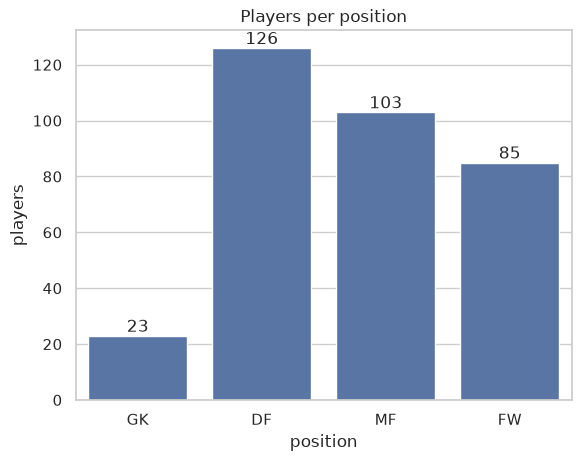

position
GK     6.8
DF    37.4
MF    30.6
FW    25.2


In [2]:
counts = df['position'].value_counts().reindex(ORDER)
ax = sns.barplot(x=counts.index, y=counts.values, order=ORDER)
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha='center', va='bottom')
ax.set_title('Players per position'); ax.set_ylabel('players')
plt.savefig('../report/figures/eda_class_counts.png', dpi=150, bbox_inches='tight'); plt.show()
print((counts / counts.sum() * 100).round(1).to_string())

## 2. Which statistics separate the positions?
The F-score measures how different the position averages are, compared with the spread inside each position. Higher = more useful for the model.

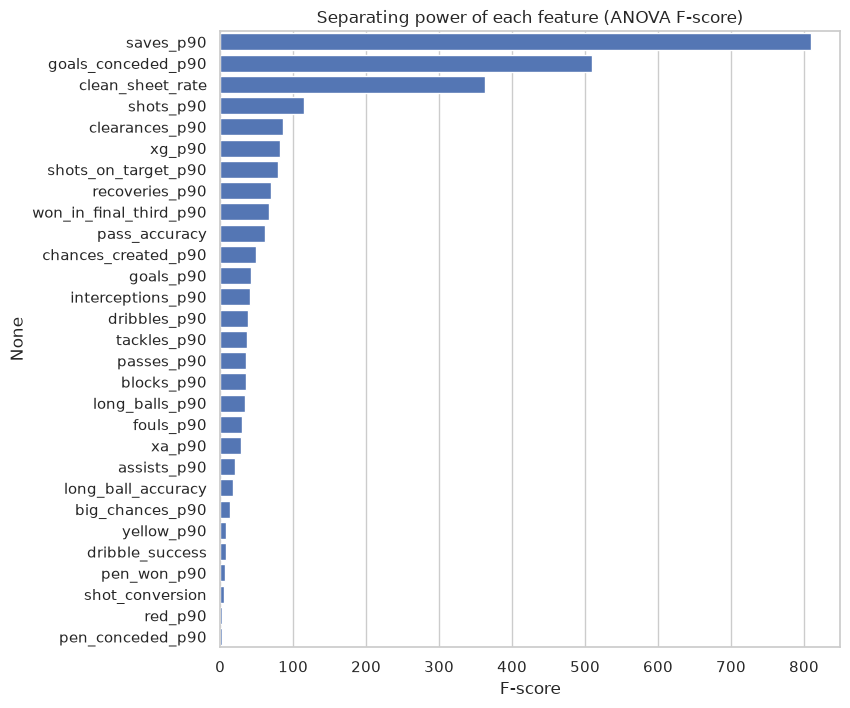

saves_p90                 809.1
goals_conceded_p90        510.1
clean_sheet_rate          363.0
shots_p90                 115.0
clearances_p90             86.6
xg_p90                     81.8
shots_on_target_p90        79.8
recoveries_p90             69.9
won_in_final_third_p90     66.7
pass_accuracy              62.1
dtype: float64

In [3]:
F, p = f_classif(df[features], df['position'])
rank = pd.Series(F, index=features).sort_values(ascending=False)
plt.figure(figsize=(8, 8))
sns.barplot(x=rank.values, y=rank.index, color='#4472C4')
plt.title('Separating power of each feature (ANOVA F-score)'); plt.xlabel('F-score')
plt.savefig('../report/figures/eda_feature_scores.png', dpi=150, bbox_inches='tight'); plt.show()
rank.head(10).round(1)

## 3. Distribution of the best features by position

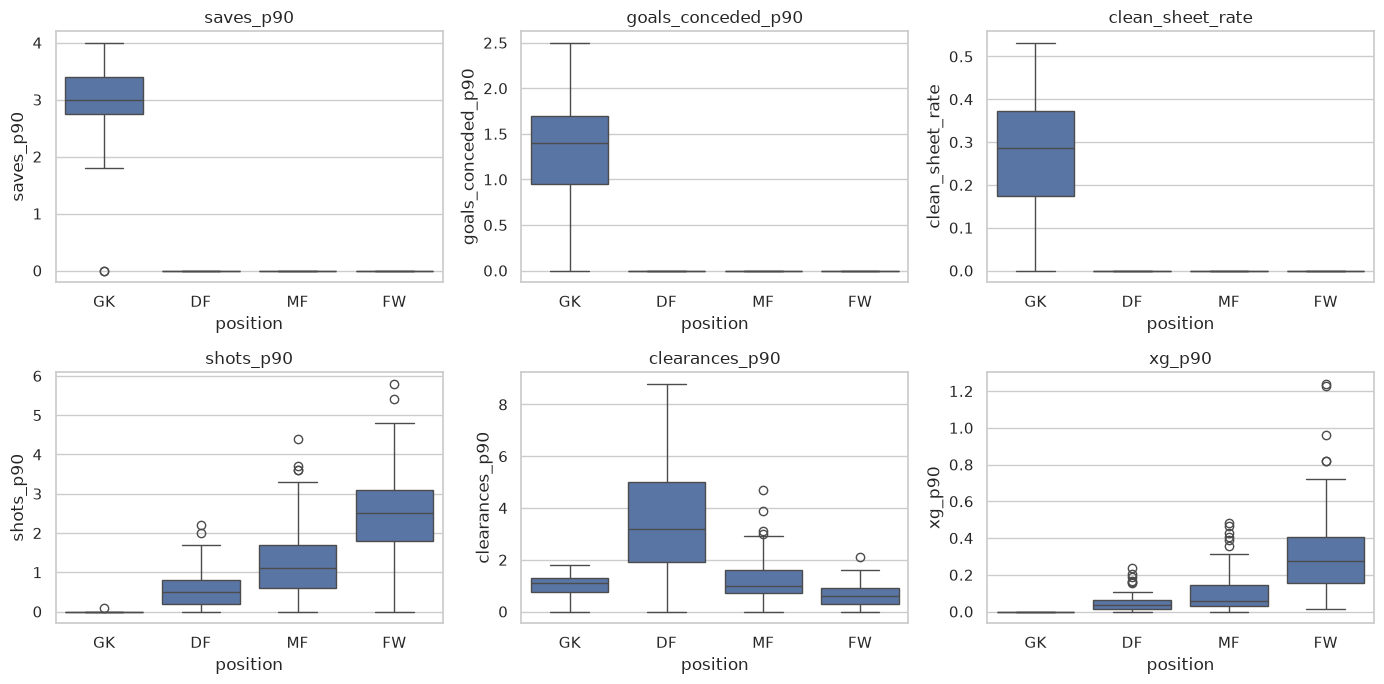

In [4]:
top6 = list(rank.index[:6])
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.flat, top6):
    sns.boxplot(data=df, x='position', y=f, order=ORDER, ax=ax)
    ax.set_title(f)
plt.tight_layout()
plt.savefig('../report/figures/eda_boxplots.png', dpi=150, bbox_inches='tight'); plt.show()

## 4. Average profile of each position
Values are scaled 0 to 1 per feature, so different units can be compared.

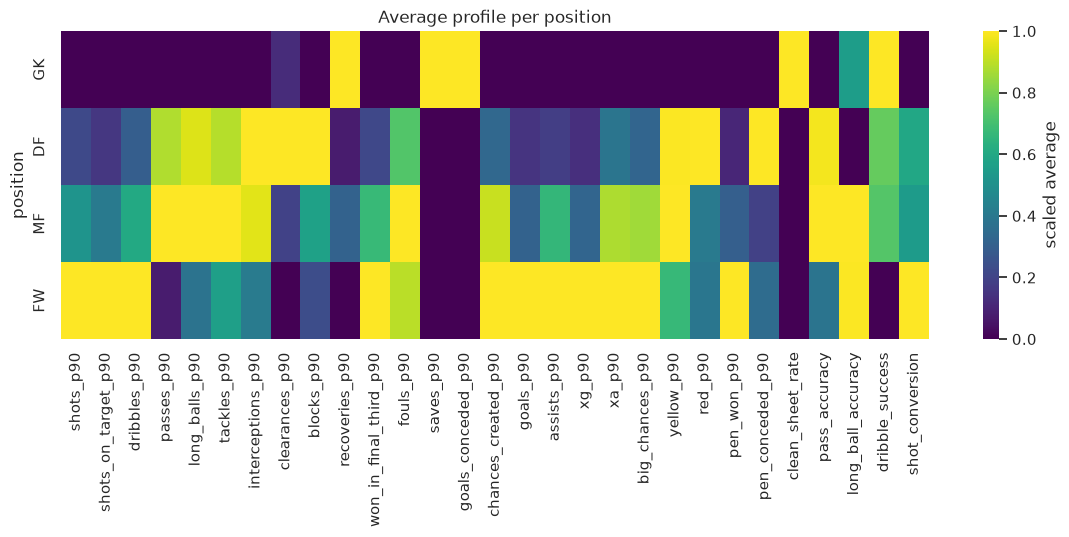

In [5]:
prof = df.groupby('position')[features].mean().reindex(ORDER)
prof_scaled = (prof - prof.min()) / (prof.max() - prof.min() + 1e-9)
plt.figure(figsize=(14, 4))
sns.heatmap(prof_scaled, cmap='viridis', cbar_kws={'label': 'scaled average'})
plt.title('Average profile per position'); plt.xticks(rotation=90)
plt.savefig('../report/figures/eda_profile_heatmap.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Correlation between features
Strongly correlated features carry the same information.

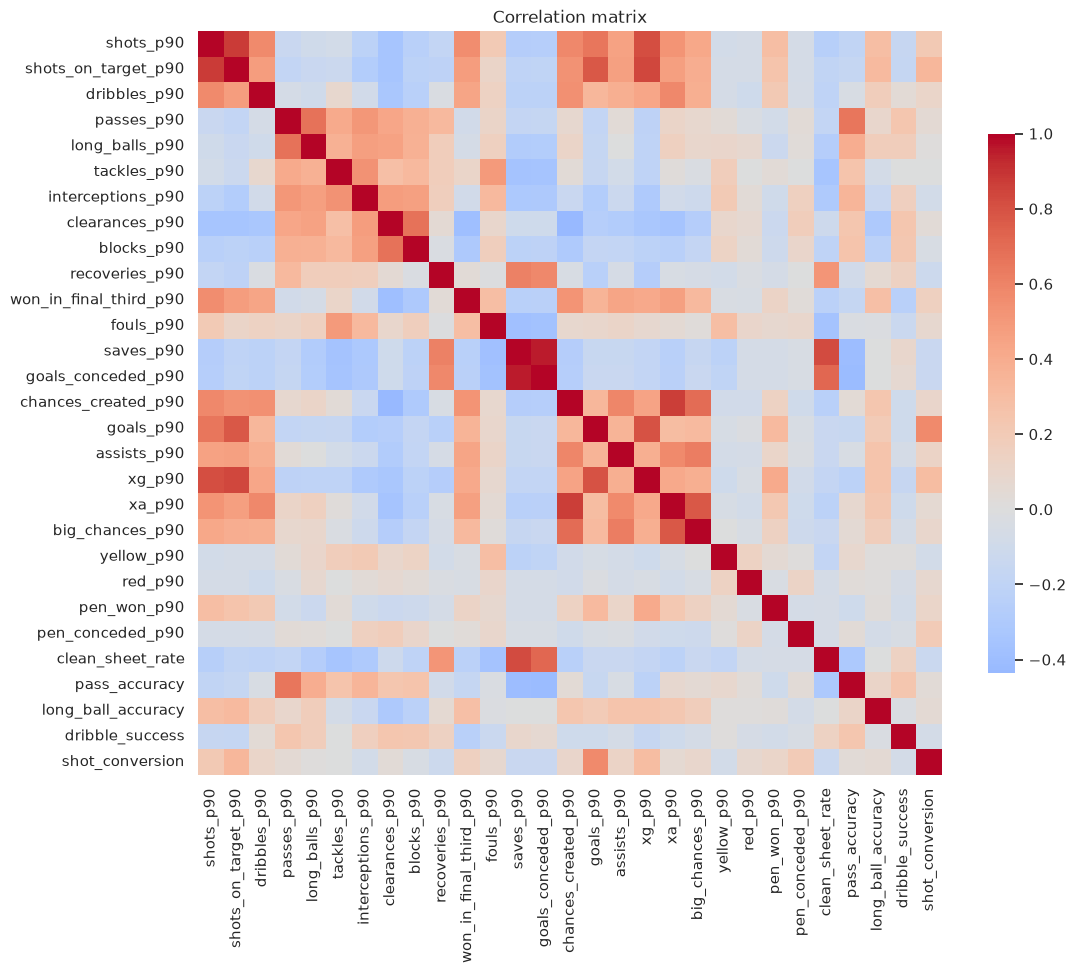

saves_p90            goals_conceded_p90     0.96
shots_p90            shots_on_target_p90    0.88
chances_created_p90  xa_p90                 0.87
dtype: float64

In [6]:
corr = df[features].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': .7})
plt.title('Correlation matrix')
plt.savefig('../report/figures/eda_correlation.png', dpi=150, bbox_inches='tight'); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
pairs[pairs.abs() > 0.85].sort_values(ascending=False).round(2)

## 6. Which positions look alike?
Average distance between position profiles (small = easy to confuse). Expect the closest pair to be among DF, MF and FW.

In [7]:
z = (df[features] - df[features].mean()) / (df[features].std() + 1e-9)
zp = z.groupby(df['position']).mean().reindex(ORDER)
dist = pd.DataFrame([[np.linalg.norm(zp.loc[a] - zp.loc[b]) for b in ORDER] for a in ORDER],
                    index=ORDER, columns=ORDER).round(2)
dist

,GK,DF,MF,FW
GK,0.00,8.02,8.34,8.86
DF,8.02,0.00,2.64,4.99
MF,8.34,2.64,0.00,3.49
FW,8.86,4.99,3.49,0.00


## 7. Train and test the models
Plan: keep 20% of the players aside as a test set that no model sees while it is built. Everything else (comparing models, choosing settings) uses only the other 80%, with 5-fold cross-validation. `minutes`, team and the player's id are NOT used as features.

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, ConfusionMatrixDisplay
import joblib

X, y = df[features], df['position']
idx_train, idx_test = train_test_split(df.index, test_size=0.2, stratify=y, random_state=42)
X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
print('train:', len(X_train), y_train.value_counts().reindex(ORDER).to_dict())
print('test :', len(X_test), y_test.value_counts().reindex(ORDER).to_dict())

train: 269 {'GK': 18, 'DF': 101, 'MF': 82, 'FW': 68}
test : 68 {'GK': 5, 'DF': 25, 'MF': 21, 'FW': 17}


### 7.1 First comparison with default settings (training players only)
The baseline always answers the most common position. A real model must beat it clearly.

In [9]:
models = {
    'Baseline (most frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
    'k-NN': Pipeline([('scale', StandardScaler()), ('clf', KNeighborsClassifier())]),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=['accuracy', 'f1_macro'])
    rows.append({'model': name, 'cv_accuracy': r['test_accuracy'].mean(), 'cv_macro_f1': r['test_f1_macro'].mean()})
pd.DataFrame(rows).set_index('model').round(3)

,cv_accuracy,cv_macro_f1
model,,
Baseline (most frequent),0.375,0.136
Logistic Regression,0.766,0.786
k-NN,0.740,0.765
Random Forest,0.766,0.786


### 7.2 Choosing the best settings for each model (training players only)

In [10]:
grids = {
    'Logistic Regression': (models['Logistic Regression'], {'clf__C': [0.03, 0.1, 0.3, 1, 3, 10]}),
    'k-NN': (models['k-NN'], {'clf__n_neighbors': [3, 5, 7, 9, 11, 15], 'clf__weights': ['uniform', 'distance']}),
    'Random Forest': (models['Random Forest'], {'max_depth': [None, 6, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ['sqrt', 0.5]}),
}
best = {}
for name, (m, g) in grids.items():
    gs = GridSearchCV(m, g, cv=cv, scoring='f1_macro', n_jobs=-1).fit(X_train, y_train)
    best[name] = gs
    print(f'{name}: cv macro-F1 = {gs.best_score_:.3f} | {gs.best_params_}')

Logistic Regression: cv macro-F1 = 0.803 | {'clf__C': 0.03}


k-NN: cv macro-F1 = 0.792 | {'clf__n_neighbors': 3, 'clf__weights': 'uniform'}


Random Forest: cv macro-F1 = 0.801 | {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2}


### 7.3 Final exam on the test players
The test players were never used above.

In [11]:
base = DummyClassifier(strategy='most_frequent').fit(X_train, y_train).predict(X_test)
results = [{'model': 'Baseline (most frequent)', 'cv_macro_f1': np.nan,
            'test_accuracy': accuracy_score(y_test, base), 'test_macro_f1': f1_score(y_test, base, average='macro')}]
preds = {}
for name, gs in best.items():
    preds[name] = gs.predict(X_test)
    results.append({'model': name, 'cv_macro_f1': gs.best_score_,
                    'test_accuracy': accuracy_score(y_test, preds[name]),
                    'test_macro_f1': f1_score(y_test, preds[name], average='macro')})
res = pd.DataFrame(results).set_index('model').round(3)
winner = res.drop('Baseline (most frequent)')['cv_macro_f1'].idxmax()
print('Best model by cross-validation:', winner)
res

Best model by cross-validation: Logistic Regression


,cv_macro_f1,test_accuracy,test_macro_f1
model,,,
Baseline (most frequent),NaN,0.368,0.134
Logistic Regression,0.803,0.853,0.877
k-NN,0.792,0.779,0.814
Random Forest,0.801,0.824,0.833


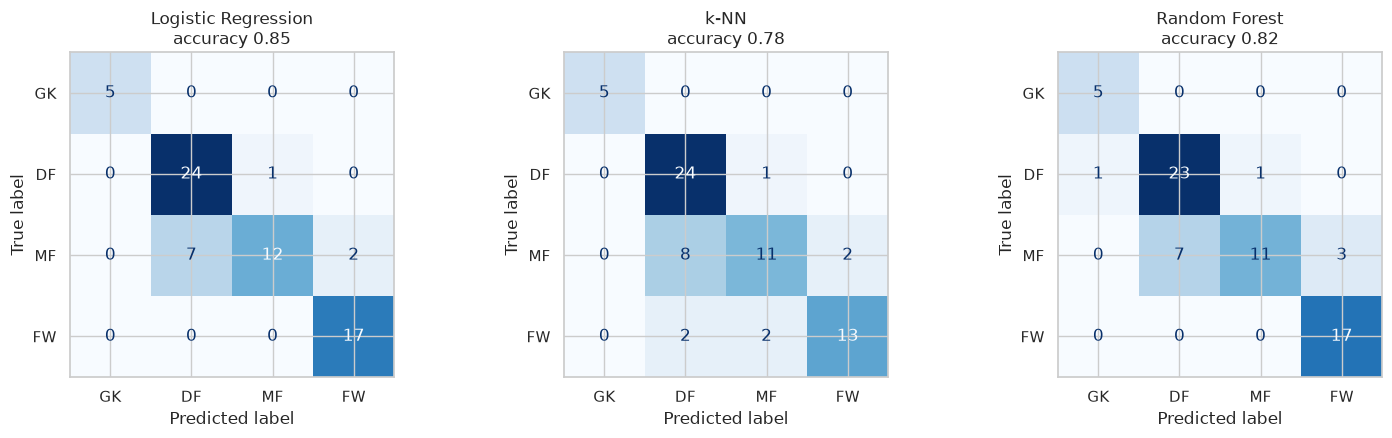

              precision    recall  f1-score   support

          GK      1.000     1.000     1.000         5
          DF      0.774     0.960     0.857        25
          MF      0.923     0.571     0.706        21
          FW      0.895     1.000     0.944        17

    accuracy                          0.853        68
   macro avg      0.898     0.883     0.877        68
weighted avg      0.867     0.853     0.843        68



In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=ORDER)
    ConfusionMatrixDisplay(cm, display_labels=ORDER).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}\naccuracy {accuracy_score(y_test, p):.2f}')
plt.tight_layout()
plt.savefig('../report/figures/ml_confusion_matrices.png', dpi=150, bbox_inches='tight'); plt.show()
print(classification_report(y_test, preds[winner], labels=ORDER, digits=3, zero_division=0))

### 7.4 More reliable score for the best model
The test set is small (only a few goalkeepers), so one split can be lucky or unlucky. Here the best model is scored 15 times (5 folds, repeated 3 times) on all players.

In [13]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)
r = cross_validate(clone(best[winner].best_estimator_), X, y, cv=rcv, scoring=['accuracy', 'f1_macro'])
print(f"{winner}: accuracy {r['test_accuracy'].mean():.3f} +/- {r['test_accuracy'].std():.3f} | "
      f"macro-F1 {r['test_f1_macro'].mean():.3f} +/- {r['test_f1_macro'].std():.3f}")

Logistic Regression: accuracy 0.795 +/- 0.048 | macro-F1 0.826 +/- 0.047


### 7.5 Which statistics did the Random Forest use most?

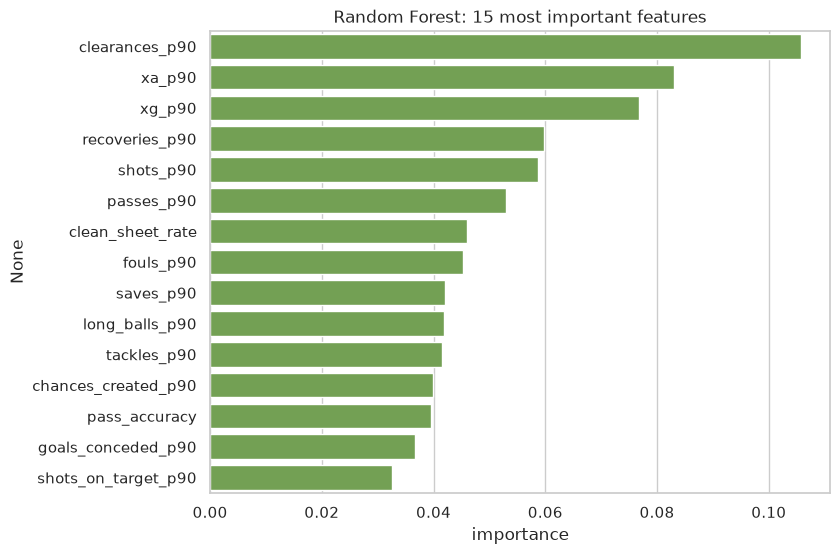

clearances_p90         0.106
xa_p90                 0.083
xg_p90                 0.077
recoveries_p90         0.060
shots_p90              0.059
passes_p90             0.053
clean_sheet_rate       0.046
fouls_p90              0.045
saves_p90              0.042
long_balls_p90         0.042
tackles_p90            0.041
chances_created_p90    0.040
pass_accuracy          0.040
goals_conceded_p90     0.037
shots_on_target_p90    0.033
dtype: float64

In [14]:
rf = best['Random Forest'].best_estimator_
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, color='#70AD47')
plt.title('Random Forest: 15 most important features'); plt.xlabel('importance')
plt.savefig('../report/figures/ml_feature_importance.png', dpi=150, bbox_inches='tight'); plt.show()
imp.round(3)

### 7.6 Which players were classified wrongly?

In [15]:
wrong = df.loc[idx_test, ['name', 'position', 'minutes']].copy()
wrong['predicted'] = preds[winner]
wrong = wrong[wrong['position'] != wrong['predicted']]
print(len(wrong), 'of', len(idx_test), 'test players wrong')
print(pd.crosstab(wrong['position'], wrong['predicted']).to_string() if len(wrong) else 'none')
wrong.sort_values('minutes', ascending=False)

10 of 68 test players wrong
predicted  DF  FW  MF
position             
DF          0   0   1
MF          7   2   0


,name,position,minutes,predicted
163,Arnaut Danjuma,MF,929.0,FW
263,Pathé Ciss,MF,925.0,DF
259,Javi Morcillo,MF,745.0,DF
272,Oriol Rey,MF,692.0,DF
206,Joaquín Muñoz,MF,481.0,FW
211,Facundo Bernal,MF,468.0,DF
285,Óscar Valentín,MF,467.0,DF
80,Diego Villares,MF,364.0,DF
98,Jules Koundé,DF,351.0,MF
266,Ander Guevara,MF,274.0,DF


## 8. The position suggestion function
The final model is trained again on all players and saved to `models/position_model.joblib`. Its quality is the one measured above (test set and repeated cross-validation), not its score on players it has already seen.

In [16]:
final = clone(best[winner].best_estimator_).fit(X, y)
RATES = ['pass_accuracy', 'long_ball_accuracy', 'dribble_success', 'shot_conversion']
medians = X.median().to_dict()
os.makedirs('../models', exist_ok=True)
joblib.dump({'model': final, 'features': features, 'medians': medians}, '../models/position_model.joblib')

def suggest_position(stats):
    """stats: dict of per-90 statistics. Missing ones count as 0 (percentages: the median)."""
    row = pd.DataFrame([{f: stats.get(f, medians[f] if f in RATES else 0.0) for f in features}])
    proba = pd.Series(final.predict_proba(row)[0], index=final.classes_).sort_values(ascending=False)
    return proba.index[0], proba.round(2).to_dict()

examples = {
    'defender-like': {'tackles_p90': 2.0, 'interceptions_p90': 1.2, 'clearances_p90': 4.0, 'passes_p90': 45, 'shots_p90': 0.3},
    'striker-like': {'shots_p90': 3.2, 'goals_p90': 0.6, 'shots_on_target_p90': 1.5, 'passes_p90': 18, 'clearances_p90': 0.4},
    'goalkeeper-like': {'saves_p90': 3.1, 'goals_conceded_p90': 1.2, 'passes_p90': 20, 'clearances_p90': 1.0},
}
for k, v in examples.items():
    print(k, '->', suggest_position(v))

defender-like -> ('DF', {'DF': 0.9, 'MF': 0.05, 'GK': 0.03, 'FW': 0.03})
striker-like -> ('FW', {'FW': 0.64, 'DF': 0.17, 'GK': 0.1, 'MF': 0.09})
goalkeeper-like -> ('GK', {'GK': 0.76, 'DF': 0.17, 'FW': 0.04, 'MF': 0.03})
